In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM, StatsBase

In [3]:
Plots.theme(:dao)

In [4]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [5]:
pwd()

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations"

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes

14-element Vector{SubString{String}}:
 "seawater"
 "oral"
 "gut"
 "vaginal"
 "terrestrial soil"
 "oral cavity"
 "feces"
 "skin"
 "glacier"
 "marine hydrothermal vents"
 "river"
 "lake"
 "environmental aquatic marine"
 "activated sludge"

In [7]:
cdata = DataFrame[]
for i in [1,2,3,4,5,6,8,9,12,13,14]
    t_data = CSV.read("./calibration_results_p0_fixed2/eco-calib-$(i).csv", DataFrame)
    push!(cdata, t_data)
end

In [8]:
cdata

11-element Vector{DataFrame}:
 10×3 DataFrame
 Row │ theta     gamma    fitness  
     │ Float64   Float64  Float64  
─────┼─────────────────────────────
   1 │ 0.697582  1.1302    5.28994
   2 │ 0.544401  1.01172   5.14817
   3 │ 0.59134   1.00869   4.05522
   4 │ 1.49568   1.32765  12.8014
   5 │ 0.600075  1.05914   4.78453
   6 │ 0.571768  1.04917   5.69756
   7 │ 0.619469  1.07371   4.27376
   8 │ 0.694804  1.05936   4.11326
   9 │ 0.766983  1.14237   2.48747
  10 │ 0.689025  1.1403    3.70591
 10×3 DataFrame
 Row │ theta       gamma     fitness 
     │ Float64     Float64   Float64 
─────┼───────────────────────────────
   1 │  0.0924504  1.00613   6.92446
   2 │ -0.367724   1.00248   6.98948
   3 │ -0.241099   1.02641   6.77657
   4 │ -0.537622   1.00918   7.38806
   5 │ -0.11696    1.01718   7.6826
   6 │ -0.0976402  0.979541  7.364
   7 │ -0.447773   0.981394  5.45259
   8 │ -0.317984   1.0089    5.14969
   9 │  0.0576005  0.984839  5.70181
  10 │  0.275056   1.04604   5.28778


In [9]:
cdata[1][!,:theta]

10-element Vector{Float64}:
 0.6975821944438831
 0.5444010427764875
 0.5913404292258653
 1.4956765945759418
 0.6000749160157254
 0.5717681730531489
 0.6194690980368854
 0.6948036153078935
 0.7669827735759325
 0.6890249868867928

In [10]:
cpal_plot =  [pal[i] for i in 0.0:1/length(cdata):1]

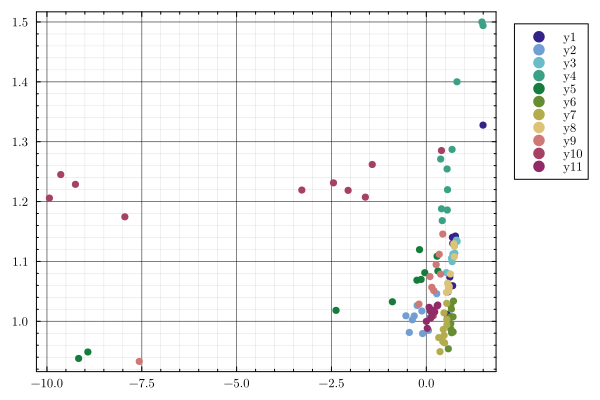

In [11]:
plot()
for i in 1:length(cdata)
    scatter!(cdata[i][!,:theta],cdata[i][!,:gamma], color = cpal_plot[i])
end  
plot!()

In [12]:
inds = [1,2,3,4,5,6,8,9,12,13,14];

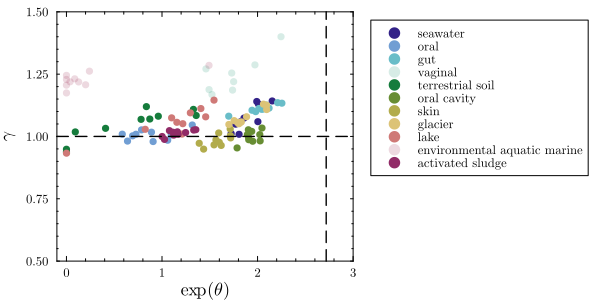

In [13]:
# note that 4 and 13 are for very small systems, let's plot them separately
plot()
for i in 1:length(cdata)
    if inds[i] in [4,13]
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], alpha = 0.2)
    else
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]])
    end
end
plot!(grid = :none, minorgrid = :none, size = (600,300), xlabel = L"\exp(\theta)", 
        ylabel = L"\gamma", ylims = [0.5,1.5], xlims = [-0.1,3])
plot!([exp(1),exp(1)], [-1,2], linestyle = :dash, color = :black, label = :none)
plot!([-2,3], [1,1], linestyle = :dash, color = :black, label = :none)

In [14]:
markers = [:circle, :rect, :diamond, :star6, :ltriangle, :utriangle, :dtriangle, :pentagon, :star5, :rtriangle, :octagon]

11-element Vector{Symbol}:
 :circle
 :rect
 :diamond
 :star6
 :ltriangle
 :utriangle
 :dtriangle
 :pentagon
 :star5
 :rtriangle
 :octagon

In [15]:
using Plots.Measures

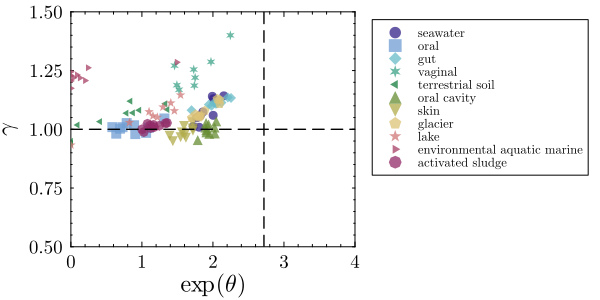

In [16]:
# note that 4 and 13 are for very small systems, let's plot them separately
plot()
for i in 1:length(cdata)
    if inds[i] in [4,13]
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], marker = markers[i], alpha = 0.75, markersize = 5)
    else
        scatter!(exp.(cdata[i][!,:theta]),cdata[i][!,:gamma], color = cpal_plot[i], label = classes[inds[i]], marker = markers[i], markersize = 5, alpha = 0.75)
    end
end
plot!(grid = :none, minorgrid = :none, size = (600,300), xlabel = L"\exp(\theta)", 
        ylabel = L"\gamma", ylims = [0.5,1.5], xlims = [0,4])
plot!([exp(1),exp(1)], [-1,2], linestyle = :dash, color = :black, label = :none)
plot!([-2,10], [1,1], linestyle = :dash, color = :black, label = :none, xlabelfontsize = 16, ylabelfontsize = 16, 
bottom_margin = 3mm, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("calibration-phase-space.pdf")

### Let's make a couple of histograms for each axis

In [19]:
length(cdata)

11

In [31]:
vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)

110-element Vector{Float64}:
  0.6975821944438831
  0.5444010427764875
  0.5913404292258653
  1.4956765945759418
  0.6000749160157254
  0.5717681730531489
  0.6194690980368854
  0.6948036153078935
  0.7669827735759325
  0.6890249868867928
  0.09245038339575105
 -0.3677240967978902
 -0.24109915782770452
  ⋮
 -1.6062350436351405
 -2.4470615668392055
  0.30293708792891666
  0.07492498233327646
  0.0014785042984051828
  0.2208598067183632
  0.025741755975329964
  0.11649853996772598
  0.1097285605230194
  0.15552298630311864
  0.28656702972930514
  0.14912221331695766

Cleaning: find indices to remove.

In [19]:
all_theta = exp.(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...));
all_gamma = vcat([cdata[x][!,:gamma] for x in 1:length(cdata)]...);

In [20]:
rm_inds = [];
for i in 1:length(all_theta)
    if all_theta[i] > 3
        push!(rm_inds,i)
    end
end

In [21]:
rm_inds

3-element Vector{Any}:
  4
 39
 40

In [22]:
all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]];

In [23]:
stephist(all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]], xlims = [0,4], fill = true, c = cpal_plot[2], nbins = 20, alpha = 0.5)
plot!(grid = false, minorgrid = false, legend = false)
plot!([0,4],[0,0], color = :black, axis = nothing, framestyle = :none)
savefig("exp-thetas.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/exp-thetas.pdf"

In [24]:
mean(log.(all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]]))

-0.3717838475397168

In [25]:
median(log.(all_theta[[x ∉ rm_inds for x in 1:length(all_theta)]]))

0.42069365480423826

In [26]:
stephist(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]], xlims = [0.5,1.5], fill = true, c = cpal_plot[end-1], nbins = 10, alpha = 0.5, xflip = true)
plot!(grid = false, minorgrid = false, axis = nothing, framestyle = :none, legend = :none)
plot!([0.5,1.5],[0,0], color = :black)
savefig("gammas.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/gammas.pdf"

In [27]:
mean(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]])

1.0740726362623574

In [28]:
median(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]])

1.0550070900936794

### Statistics of $\gamma$ and $\theta$

In [29]:
mean(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]])

1.0740726362623574

In [30]:
std(all_gamma[[x ∉ rm_inds for x in 1:length(all_gamma)]])

0.09116055783763106

In [35]:
mean(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)[[x ∉ rm_inds for x in 1:length(all_theta)]])

-0.3717838475397168

In [32]:
vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)[[x ∉ rm_inds for x in 1:length(all_theta)]]

107-element Vector{Float64}:
  0.6975821944438831
  0.5444010427764875
  0.5913404292258653
  0.6000749160157254
  0.5717681730531489
  0.6194690980368854
  0.6948036153078935
  0.7669827735759325
  0.6890249868867928
  0.09245038339575105
 -0.3677240967978902
 -0.24109915782770452
 -0.5376223919043147
  ⋮
 -1.6062350436351405
 -2.4470615668392055
  0.30293708792891666
  0.07492498233327646
  0.0014785042984051828
  0.2208598067183632
  0.025741755975329964
  0.11649853996772598
  0.1097285605230194
  0.15552298630311864
  0.28656702972930514
  0.14912221331695766

In [37]:
iqr(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)[[x ∉ rm_inds for x in 1:length(all_theta)]])

0.6225476446726002

In [42]:
percentile(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)[[x ∉ rm_inds for x in 1:length(all_theta)]], 75)

0.6361577748094678

In [33]:
std(vcat([cdata[x][!,:theta] for x in 1:length(cdata)]...)[[x ∉ rm_inds for x in 1:length(all_theta)]])

2.384331359505023

# Making a variant that encode species richness

# Now, let's choose some specific points to emphasize.

In [99]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

# example 1

In [581]:
ind_choice = 13;

In [582]:
gd_classes[ind_choice];

In [583]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [584]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

3324.0

Let's choose the smallest of these systems as the initial condition.

In [585]:
argmin(sizes)

27

In [586]:
small_to_large = sortperm(sizes);

In [587]:
# ic_sys = data[argmin(sizes)]
# ic_sys = sort(ic_sys[!,:count],rev=true)
# scatter(ic_sys, xaxis = :log, yaxis = :log)
# scatter!(sort(data[small_to_large[2]][!,:count],rev=true))
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [588]:
sum(ic_sys)

306.0

In [589]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

72.2880905754131

Let's import the calibration results.

In [590]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,-9.24904,1.22877,2.71159
2,-2.0609,1.21869,1.14574
3,-9.93465,1.20581,3.7354
4,-3.28113,1.21921,0.943988
5,-7.94649,1.17448,1.08234
6,-1.42477,1.26189,0.964386
7,-9.63609,1.24506,2.38045
8,0.400026,1.2852,0.726617
9,-1.60624,1.20736,1.1988


In [591]:
calib_results[1,1]

-9.249042707667645

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [592]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 5;
idx = top10i[size_order]

38

In [593]:
sum(sort(data[idx][!,:count],rev=true))

2217.0

In [594]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

In [595]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
scatter!(guess_sim, label = "sim.", xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, color = cpal_plot[end-1], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"\theta = -7.95, \gamma = 1.17, N=2,217")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
# savefig("ex1a.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/ex1a.pdf"

In [596]:
# scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
# scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

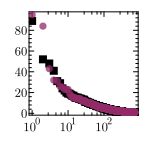

In [597]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log, marker = :rect, color = :black)
scatter!(guess_sim, label = "sim. guess", grid = false, minorgrid = false, color = cpal_plot[end-1], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (150,150), legend = :none)
# savefig("ex1b.pdf")

# example 2

In [598]:
ind_choice = 1;

In [599]:
gd_classes[ind_choice];

In [600]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [601]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

492477.0

Let's choose the smallest of these systems as the initial condition.

In [602]:
argmin(sizes)

439

In [603]:
small_to_large = sortperm(sizes);

In [604]:
# ic_sys = data[argmin(sizes)]
# ic_sys = sort(ic_sys[!,:count],rev=true)
# scatter(ic_sys, xaxis = :log, yaxis = :log)
# scatter!(sort(data[small_to_large[2]][!,:count],rev=true))
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [605]:
sum(ic_sys)

9424.0

In [606]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

3.479563394700048

Let's import the calibration results.

In [607]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.697582,1.1302,5.28994
2,0.544401,1.01172,5.14817
3,0.59134,1.00869,4.05522
4,1.49568,1.32765,12.8014
5,0.600075,1.05914,4.78453
6,0.571768,1.04917,5.69756
7,0.619469,1.07371,4.27376
8,0.694804,1.05936,4.11326
9,0.766983,1.14237,2.48747


In [608]:
calib_results[1,1]

0.6975821944438831

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [609]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 6;
idx = top10i[size_order]

223

In [610]:
sum(sort(data[idx][!,:count],rev=true))

177316.0

In [611]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

In [612]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
scatter!(guess_sim, label = "sim.", xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, color = cpal_plot[1], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"\theta = 0.57, \gamma = 1.05, N=177,316")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
savefig("ex2a.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/ex2a.pdf"

In [613]:
# scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
# scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

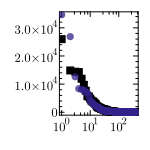

In [614]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log, marker = :rect, color = :black)
scatter!(guess_sim, label = "sim. guess", grid = false, minorgrid = false, color = cpal_plot[1], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (150,150), legend = :none)
# savefig("ex2b.pdf")

# example 3

In [615]:
ind_choice = 12;

In [616]:
gd_classes[ind_choice];

In [617]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [618]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

205465.0

Let's choose the smallest of these systems as the initial condition.

In [619]:
argmin(sizes)

42

In [620]:
small_to_large = sortperm(sizes);

In [621]:
# ic_sys = data[argmin(sizes)]
# ic_sys = sort(ic_sys[!,:count],rev=true)
# scatter(ic_sys, xaxis = :log, yaxis = :log)
# scatter!(sort(data[small_to_large[2]][!,:count],rev=true))
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [622]:
sum(ic_sys)

32514.0

In [623]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

14.704079665851605

Let's import the calibration results.

In [624]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.0959447,1.07465,4.7334
2,-7.56647,0.93295,24.5357
3,0.19681,1.0512,6.54301
4,0.376414,1.07874,6.20984
5,0.434455,1.14572,6.26094
6,0.144514,1.05677,6.4174
7,0.259881,1.09473,7.08671
8,0.190514,1.00957,7.52686
9,0.341198,1.11199,6.11035


In [625]:
calib_results[1,1]

0.09594472751594771

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [626]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 6;
idx = top10i[size_order]

4

In [627]:
sum(sort(data[idx][!,:count],rev=true))

131378.0

In [628]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

In [629]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
scatter!(guess_sim, label = "sim.", xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, color = cpal_plot[end-2], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"\theta = 0.14, \gamma = 1.06, N=131,378")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
savefig("ex3a.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/ex3a.pdf"

In [630]:
# scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
# scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

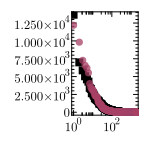

In [631]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log, marker = :rect, color = :black)
scatter!(guess_sim, label = "sim. guess", grid = false, minorgrid = false, color = cpal_plot[end-2], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (150,150), legend = :none)
# savefig("ex3b.pdf")

# example 4

In [632]:
ind_choice = 6;

In [633]:
gd_classes[ind_choice];

In [634]:
data = gd_classes[ind_choice];

We need to get the size of each of these systems.

In [635]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

59759.0

Let's choose the smallest of these systems as the initial condition.

In [636]:
argmin(sizes)

346

In [637]:
small_to_large = sortperm(sizes);

In [638]:
# ic_sys = data[argmin(sizes)]
# ic_sys = sort(ic_sys[!,:count],rev=true)
# scatter(ic_sys, xaxis = :log, yaxis = :log)
# scatter!(sort(data[small_to_large[2]][!,:count],rev=true))
ic_sys = sort(data[small_to_large[2]][!,:count],rev=true);

In [639]:
sum(ic_sys)

5683.0

In [640]:
# need to find the bounding value of p0
logxs = log10.(sum.([x[!,:count] for x in data]));
logys = log10.(length.([x[!,:count] for x in data]));
df = DataFrame(y = logys, x = logxs);
glm = lm(@formula(y ~ x), df);
a,b = coef(glm);
θ = 2+1/(b-1);
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)));
p0_guess = α*b*10^a

1.829608314092498

Let's import the calibration results.

In [641]:
calib_results = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/calibration_results_p0_fixed2/eco-calib-$(ind_choice).csv", DataFrame)

Row,theta,gamma,fitness
,Float64,Float64,Float64
1,0.661997,1.02037,2.93821
2,0.704764,1.00746,2.35486
3,0.645872,0.987012,1.0958
4,0.706524,0.98226,2.22814
5,0.715997,1.03381,2.98273
6,0.645311,0.996235,1.73135
7,0.579885,0.954036,2.33085
8,0.643776,1.02685,1.33038
9,0.638408,1.00744,1.97999


In [642]:
calib_results[1,1]

0.6619971692382136

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [643]:
top10i = sortperm(sizes,rev=true)[1:10];
size_order = 7;
idx = top10i[size_order]

23

In [644]:
sum(sort(data[idx][!,:count],rev=true))

48314.0

In [645]:
guess_sim = dsim.create_cell(calib_results[size_order,1],calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);
# guess_sim = dsim.create_cell(-10,calib_results[size_order,2], p0_guess, convert(Int64,sizes[idx]), ic_sys, :pdf);

In [646]:
scatter(sort(data[idx][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data", marker = :rect, color = :black)
scatter!(guess_sim, label = "sim.", xlabel = "rank", ylabel = "frequency", grid = false, minorgrid = false, color = cpal_plot[6], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (300,300), legend = :topright, title = L"\theta = 0.58, \gamma = 1.02, N=48,314")
plot!(xlabelfontsize = 16, ylabelfontsize = 16, legendfontsize = 8, xtickfontsize = 12, ytickfontsize = 12)
savefig("ex4a.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Calibrations/ex4a.pdf"

In [647]:
# scatter(sort(data[idx][!,:count],rev=true), label = "data", yaxis = :log)
# scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

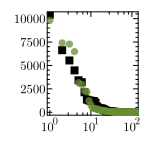

In [648]:
scatter(sort(data[idx][!,:count],rev=true), label = "data", xaxis = :log, marker = :rect, color = :black)
scatter!(guess_sim, label = "sim. guess", grid = false, minorgrid = false, color = cpal_plot[6], alpha = 0.75)
plot!(grid = :none, minorgrid = :none, size = (150,150), legend = :none)
# savefig("ex4b.pdf")

In [650]:
exp(0.58)

1.7860384307500734